# Fitting Roman L2 images (`psf_fomo.piff_datafit`)

This notebook fits the PSF of a Roman L2 image (one exposure of one SCA) with Piff. The
workflow has four pieces:

1. **`L2Image`**: the image file (science image, mask, weights, sky level, WCS);
2. **`StarCatalog`**: the detection catalog and the rule that picks the PSF stars from it;
3. **`PiffDataFit`**: the fit, with the same `PiffFitConfig` models as for simulations
   (`03_piff_validation.ipynb`);
4. **`PiffDataFitResult`**: star tables, moments, plots, reference optimum.

Real data have no truth: a model is judged by how well it matches the stars (residual images,
χ², moments of data vs model, reserve stars), and by comparing models with each other.

- **Part A** runs everything on a **synthetic L2 file** made from a simulation, so the
  workflow can be tried without real data (and, there only, compared with the truth).
- **Part B** shows the same steps for **your own L2 file**; its cells are skipped until you set
  the two paths.

The input file layout (L2 images converted from ASDF to FITS) is described in
[`docs/piff_datafit.md`](../docs/piff_datafit.md); units and definitions in
[`docs/conventions.md`](../docs/conventions.md). As in `03_piff_validation.ipynb`, the Piff
models are monochromatic (the `PiffFitConfig` default). Nothing in this notebook is kept on disk.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from cycler import cycler
from matplotlib.ticker import MaxNLocator
from astropy.table import Table
from IPython.display import display

from psf_fomo.sim import RomanSimulation
from psf_fomo.moments.measure import make_star, measure_star
from psf_fomo.piff_simfit import PiffFitConfig, compare_fits
from psf_fomo.piff_simfit.plotting import mean_images
from psf_fomo.piff_datafit import L2Image, StarCatalog, PiffDataFit, plot_size_mag
from psf_fomo.piff_datafit.synthetic import simulation_to_l2
from psf_fomo.reference import comparison_table

**Plot style.** The same style as the previous notebooks, with one color per model.

In [2]:
BACKGROUND, TEXT, MUTED, GRID = "white", "black", "dimgray", "gainsboro"
COLOR_CYCLE = ["royalblue", "darkorange", "mediumseagreen", "goldenrod", "hotpink", "green",
               "slateblue", "crimson"]
DATA_COLOR = MUTED
MODEL_COLORS = {"pinned": "darkorange", "realistic": "royalblue"}

plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": BACKGROUND, "axes.facecolor": BACKGROUND,
    "font.size": 12, "text.color": TEXT,
    "axes.titlesize": 13, "axes.titleweight": "semibold", "axes.titlelocation": "left",
    "axes.titlepad": 10, "axes.labelsize": 12, "axes.labelcolor": MUTED,
    "axes.edgecolor": "darkgray", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelsize": 11, "ytick.labelsize": 11,
    "legend.frameon": False, "legend.fontsize": 10,
    "lines.linewidth": 2, "lines.markersize": 7, "errorbar.capsize": 0,
    "axes.prop_cycle": cycler(color=COLOR_CYCLE),
})

**Helpers for the plots and tables** (the `psf_fomo` calls are written out in the sections
below):

- `plot_image`: the image file (sky subtracted, contrast-stretched) with the catalog
  positions;
- `plot_residuals`: mean data − model over the fit stars on the native pixels, as a fraction
  of the peak, one panel per model;
- `plot_data_vs_model`: histograms of `T`, `e1`, `e2` (`wmom` 0.4″, native) of the data and
  of each model, measured on the same stamps;
- `fit_table`: the main numbers of each fit; `fmt` rounds the numbers of a table for display.

In [3]:
QUANTITIES = {"T": "T [arcsec²]", "e1": "e1", "e2": "e2"}


def _number(v):
    # 4 decimals above 1, 4 significant digits from 1e-3 to 1, scientific notation otherwise.
    if v == 0 or 1 <= abs(v) < 1e4:
        return f"{v:.4f}"
    return f"{v:.4g}" if 1e-3 <= abs(v) < 1 else f"{v:.3e}"


def fmt(table):
    for name in table.colnames:
        if table[name].dtype.kind == "f":
            table[name].info.format = _number
    return table


def plot_image(img, cat, title):
    data = img.array("image") - img.sky                     # DN/s
    noise = 1.4826 * np.median(np.abs(data - np.median(data)))
    fig, ax = plt.subplots(figsize=(7, 7))
    ax.imshow(np.arcsinh(data / noise), origin="lower", cmap="gray")
    x, y = cat.table["x"], cat.table["y"]                   # 0-based, like the image array
    ax.scatter(x, y, s=80, facecolors="none", edgecolors="crimson", lw=0.8)
    ax.set(title=title, xlabel="x [pix]", ylabel="y [pix]")
    ax.grid(False)
    return fig


def plot_residuals(fits):
    images = {}
    for label, res in fits.items():
        stars, _ = res.selected_stars("fit")
        mean = mean_images(res.psf, stars)
        images[label] = mean["resid"] / mean["data"].max()
    lim = max(np.abs(im).max() for im in images.values())
    fig, axes = plt.subplots(1, len(images), figsize=(5.6 * len(images), 4.8), squeeze=False)
    for ax, (label, image) in zip(axes[0], images.items()):
        im = ax.imshow(image, origin="lower", cmap="RdBu_r", vmin=-lim, vmax=lim)
        fig.colorbar(im, ax=ax, shrink=0.85, label="fraction of the peak")
        ax.set(title=f"{label}: data − model", xticks=[], yticks=[])
        ax.grid(False)
    fig.tight_layout()
    return fig


def bin_edges(values, n_stars):
    # Few stars: about √N bins (5 to 15) over the common range.
    n_bins = int(np.clip(round(np.sqrt(n_stars)), 5, 15))
    lo, hi = np.min(values), np.max(values)
    pad = max(0.05 * (hi - lo), 1e-6 * max(abs(lo), abs(hi), 1e-12))
    return np.linspace(lo - pad, hi + pad, n_bins + 1)


def plot_data_vs_model(fits, algorithm="wmom_0.4"):
    tables = {}
    for label, res in fits.items():
        m = res.moments
        tables[label] = m[(m["comparison"] == "data") & (m["algorithm"] == algorithm)
                          & (m["flag"] == 0)]
    data = next(iter(tables.values()))                      # the same stamps in every fit
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
    for ax, (q, label) in zip(axes, QUANTITIES.items()):
        values = np.concatenate([data[q + "_ref"]] + [t[q + "_model"] for t in tables.values()])
        edges = bin_edges(values, len(data))
        ax.hist(data[q + "_ref"], bins=edges, color=DATA_COLOR, alpha=0.3, label="data")
        for name, t in tables.items():
            ax.hist(t[q + "_model"], bins=edges, histtype="step", lw=2,
                    color=MODEL_COLORS[name], label=name)
        ax.yaxis.set_major_locator(MaxNLocator(integer=True))
        ax.set(title=f"{q}, native, {algorithm}", xlabel=label, ylabel="stars")
    axes[0].legend()
    fig.tight_layout()
    return fig


def fit_table(fits):
    keys = ("chisq_dof", "niter", "converged", "n_catalog", "n_candidates", "n_stars",
            "n_reserve", "n_flagged", "seconds")
    return fmt(Table(rows=[{"model": label, **{k: res.fit_summary[k] for k in keys}}
                           for label, res in fits.items()]))

# Part A: a synthetic L2 file

## A.1 From a simulation to an L2 file

80 stars at random positions on SCA 5, magnitude 18 to 21, with the Roman WCS (a real
celestial WCS, as in L2 files) and drawn chromatically (the simulation default). The
noiseless image is kept (`save_noiseless=True`): `simulation_to_l2` turns it into an L2 file
in DN/s with its own sky, Poisson and read noise, together with a detection catalog of the
stars (true positions and fluxes). Like real L2 files, it is in Roman's science frame, the
frame of `galsim.roman`'s WCS and PSFs.

In [4]:
builder = RomanSimulation(scas=[5], n_stars=80, seed=1)    # default placement: random
builder.set_wcs("roman")                                   # default "simple" (no sky coordinates)
builder.set_brightness(mag_range=(18, 21))
sim = builder.run(save_noiseless=True)                     # default save_noiseless=False

synth = simulation_to_l2(sim, sca=5, sky=0.6)
# defaults: folder=None (temporary folder, removed with `synth` or at exit), obs=0,
#           sky=0.6 [DN/s per pixel], seed=0
synth

SyntheticL2(temporary: l2_sca05.fits, det_sca05.fits)

## A.2 The image: `L2Image`

`L2Image` reads the file: by default the uniform-weight planes, also called data+dumo (`variant="unif"`: `SCI_UNIF`,
`MASK_UNIF`, `IVAR_UNIF`, `GAIN_UNIF`; `variant="standard"` uses `SCI`, `MASK`, `IVAR`,
`GAIN` and is equivalent to just data), the sky level `SKYBKG` (subtracted before the fit), SCA and filter from the header.
L2 files, `galsim.roman` and so Piff's `RomanOptics` all use Roman's science frame, so files
are fitted as they are.

In [5]:
img = L2Image(synth.image_file)
# defaults: variant="unif", sca and filter_name from the header, pointing from the header
print(f"SCA {img.sca}, filter {img.filter_name}, sky {img.sky:.3f} DN/s")

SCA 5, filter H158, sky 0.600 DN/s


Checks before a fit: `check_orientation` (the file's pixel frame against `galsim.roman`'s: a
mirrored axis or a wrong pixel scale raises), `check_weights` (the weights must not contain the stars'
own Poisson noise; nothing to check for the uniform planes) and `check_finite` (pixels whose
image or weight is not a number; a fit cleans them in a working copy, your file is never
changed). `PiffDataFit.run` runs
them too and stores the results in `res.checks`.

In [6]:
print("orientation:", img.check_orientation())
print("weights:    ", img.check_weights())
print("non-finite: ", img.check_finite())

orientation: {'parity_ok': True, 'scale': 0.10765131569628196, 'rotation_deg': None}
weights:     None
non-finite:  {'total': 0, 'unmasked': 0}


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


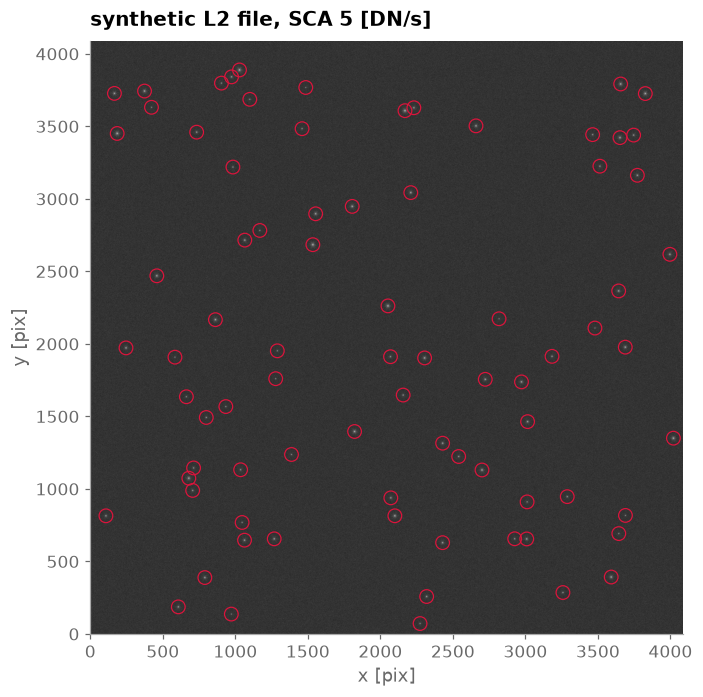

In [7]:
plot_image(img, StarCatalog(synth.catalog_file), "synthetic L2 file, SCA 5 [DN/s]")
plt.show()

## A.3 The catalog: `StarCatalog`

`StarCatalog` reads a detection catalog (a SEP-style FITS table, or an astropy `Table`), with
0-based `x`, `y`, a flux (`flux_auto`, DN/s), a size (`r50`) and a `clean` flag. Two choices
pick the PSF stars:

- **selection** `select_stars(method)`: `"sizemag"` (Piff's star finder on the stellar locus,
  for catalogs with galaxies; the default), `"all"` (every detection; here, since the
  synthetic catalog holds only stars) or `"column"` (a flag column);
- **cuts** `set_cuts(...)`: Piff's rejection step after the selection.

In [8]:
cat = StarCatalog(synth.catalog_file)
# defaults: hdu=1, id_col="id", x_col="x", y_col="y", zero_based=True, flux_col="flux_auto",
#           size_col="r50", clean_col="clean", extra_cols=()
cat.select_stars("all")                    # default "sizemag"
cat.set_cuts(clean_only=True, min_sep=2.5, min_snr=None, max_mask_pixels=None)
# these are the defaults; also: max_snr_weight=None (Piff's 100: the S/N of bright stars is
# capped at 100), reject_where=None (an expression on catalog columns), nstars=None

**Before fitting.** `measure` measures the moments of every detection on the stamps a fit
would use, and with `preview_selection=True` also runs the selection and the cuts (no fit), so
you can see which objects would be fitted. The size–magnitude diagram shows the stellar locus.

/users/PCON0003/berlfein/projects/psf_fomo/GalSim/galsim/errors.py:453: GalSimWarning: No C++ Image template instantiation for data type <class 'numpy.uint8'>. Using numpy.float64 instead.
  warnings.warn(message, GalSimWarning)
findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


80 detections measured, 80 pass the selection and the cuts


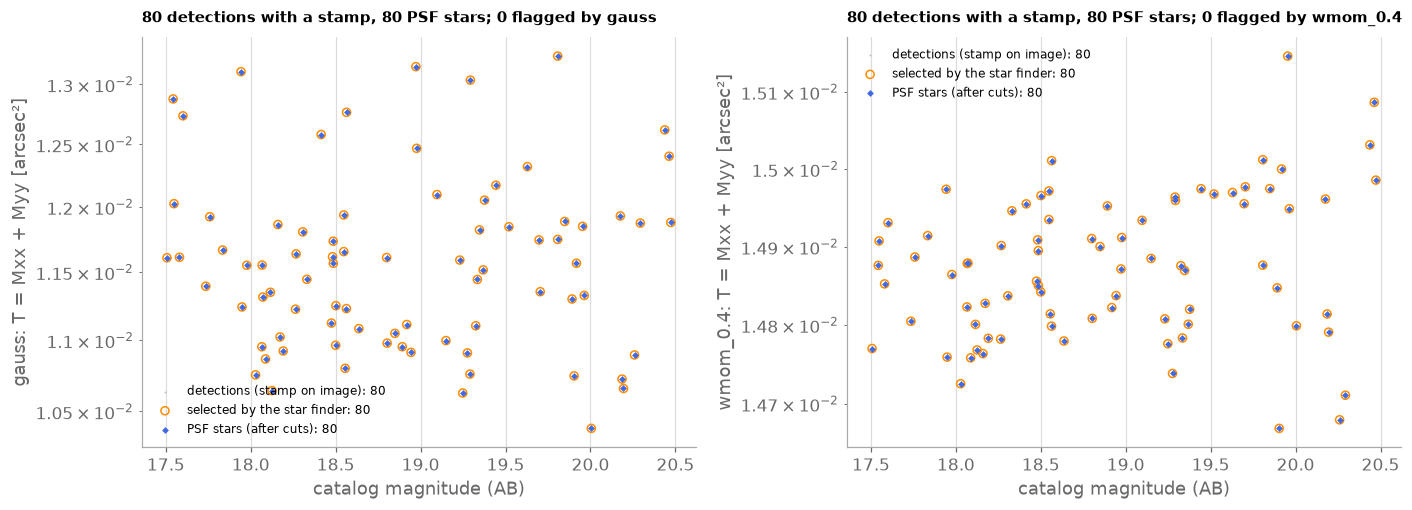

In [9]:
measured = cat.measure(img, algorithms=("gauss", "wmom"), wmom_fwhm=(0.4,),
                       preview_selection=True)
# defaults: algorithms=("gauss",), wmom_fwhm=(0.4,), stamp_size=25, mag_range=None,
#           max_objects=None, preview_selection=False
print(f"{len(measured)} detections measured, {int(measured['star'].sum())} pass the "
      "selection and the cuts")
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
plot_size_mag(measured, algorithm="gauss", ax=axes[0])
plot_size_mag(measured, algorithm="wmom_0.4", ax=axes[1])
fig.tight_layout()
plt.show()

## A.4 Fitting: `PiffDataFit`

The same two models as in `03_piff_validation.ipynb`: **pinned** optics (+ the fixed MTF),
and a **realistic** model with free optics (Z4 … Z11), a `GaussianBlur` and a `PixelGrid`.
`PiffDataFit` takes the image, the catalog and the model; `run()` writes Piff's inputs (catalog,
configuration, a cleaned copy of the image if needed) to a temporary folder, runs Piff's own input,
selection and fit, and returns a `PiffDataFitResult` in memory.

In [10]:
pinned = PiffFitConfig()
pinned.set_optics("pinned")

realistic = PiffFitConfig()
realistic.set_optics("free", max_zernike=11, prior_sigma=0.05)
realistic.add_kernel("blur", order=1)
realistic.add_pixelgrid(size=5, scale=0.11, order=1)


def data_fit(img, cat, cfg, name=None):
    fit = PiffDataFit(img, cat, cfg, name=name)
    fit.set_reserve(frac=0.2, seed=1)        # default frac=0.2, seed=0 (none without the call)
    fit.set_diagnostics(native=("wmom",), wmom_fwhm=(0.4,), oversampled=("hsm",))
    # defaults: native=("wmom", "gauss"), oversampled=("hsm",), comparisons=("data", "model_os")
    # Also: fit.set_stamp_size(25), fit.set_verbose(1) (Piff's log; default 0 = errors only)
    return fit.run()                         # save_to=None (default): nothing kept on disk


fits = {"pinned": data_fit(img, cat, pinned, "pinned"),
        "realistic": data_fit(img, cat, realistic, "realistic")}

/users/PCON0003/berlfein/projects/psf_fomo/GalSim/galsim/errors.py:453: GalSimWarning: No C++ Image template instantiation for data type <class 'numpy.uint8'>. Using numpy.float64 instead.
  warnings.warn(message, GalSimWarning)
/users/PCON0003/berlfein/projects/psf_fomo/GalSim/galsim/errors.py:453: GalSimWarning: No C++ Image template instantiation for data type <class 'numpy.uint8'>. Using numpy.float64 instead.
  warnings.warn(message, GalSimWarning)


`fit_summary` describes each fit: χ²/dof, Piff iterations, whether Piff converged, and the
star counts at each step (`n_catalog` detections, `n_candidates` picked by the selection,
`n_stars` fitted + reserve after the cuts). `res.checks` holds the image checks; `res.table`
has one row per star (position `x`, `y`, `flux_cat_r` = fitted / catalog flux,
`sky_resid`, χ²/dof, ...).

In [11]:
display(fit_table(fits))
print(fits["realistic"].checks)
fmt(fits["realistic"].table["star_id", "x", "y", "reserve", "flag", "flux_cat_r",
                            "sky_resid", "chisq_dof"][:4])

/tmp/ipykernel_359362/895962487.py:8: FutureWarning: Format strings passed to MaskedConstant are ignored, but in future may error or produce different behavior
  return f"{v:.4g}" if 1e-3 <= abs(v) < 1 else f"{v:.3e}"


model,chisq_dof,niter,converged,n_catalog,n_candidates,n_stars,n_reserve,n_flagged,seconds
str9,float64,int64,bool,int64,int64,int64,int64,int64,float64
pinned,0.0109,2,True,80,80,80,16,0,254.4108
realistic,0.01046,2,True,80,80,80,16,0,982.7921


{'weights_ratio': None, 'orientation': {'parity_ok': True, 'scale': 0.10765131569628196, 'rotation_deg': None}, 'nonfinite': {'total': 0, 'unmasked': 0}, 'attitude': {'requested': False, 'used': False, 'values': None}}


star_id,x,y,reserve,flag,flux_cat_r,sky_resid,chisq_dof
,pix,pix,,,,adu / s,
int64,float64,float64,bool,int64,float64,float64,float64
1,4021.6764,1350.6977,False,0,0.9977,0.1287,0.001576
2,3259.8775,286.2873,False,0,1.0038,0.03848,0.007731
3,1806.9753,2948.8095,True,0,0.9989,0.1091,0.001695
4,186.4563,3451.6466,False,0,0.9886,0.1672,0.001154


**Residual images.** Mean data − model over the fit stars on the native pixels, as a fraction
of the peak, same color scale for both models.

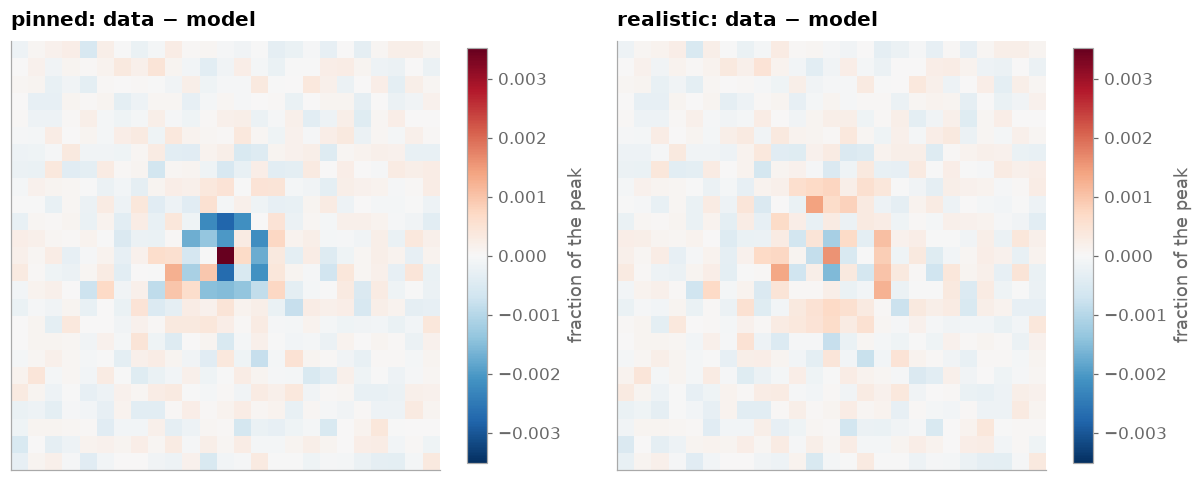

In [12]:
plot_residuals(fits)
plt.show()

**Moments of data and model.** For every star (fit and reserve) the data stamp and the model
drawn on the same stamp (fitted flux and center) are measured the same way (`wmom` 0.4″,
about the catalog position): data in gray, models as outlines.

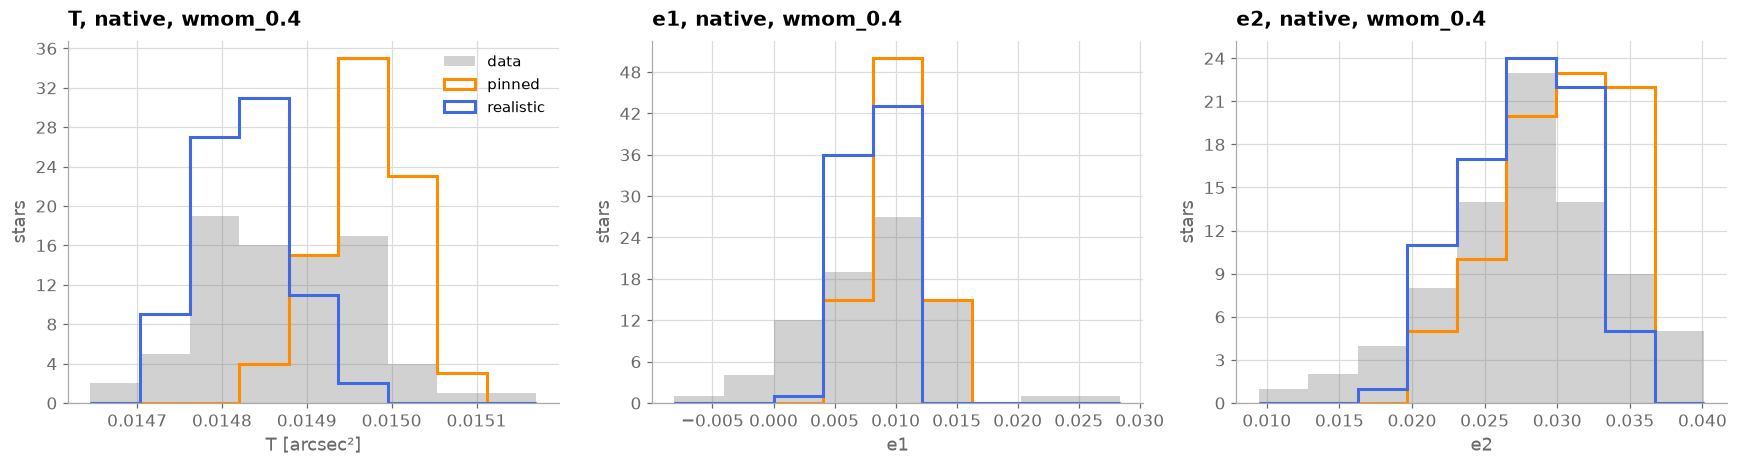

In [13]:
plot_data_vs_model(fits)
plt.show()

**Sky residual.** The median of the stamp-edge pixels after the sky subtraction, per star,
across the SCA: an offset means a wrong sky level, a trend a sky gradient.

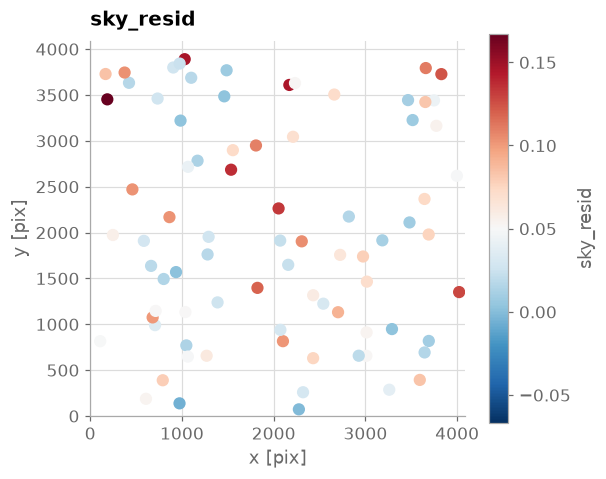

In [14]:
fits["realistic"].plot_field("sky_resid")
plt.show()

## A.5 The fitted model

**Across the SCA.** `model_moments` measures the fitted model alone, oversampled ×5 (`hsm`),
on a 5 × 5 grid of SCA positions. `compare_fits` measures several fits at the same positions
(by default the stars of the first fit) and gives their differences from the first one.

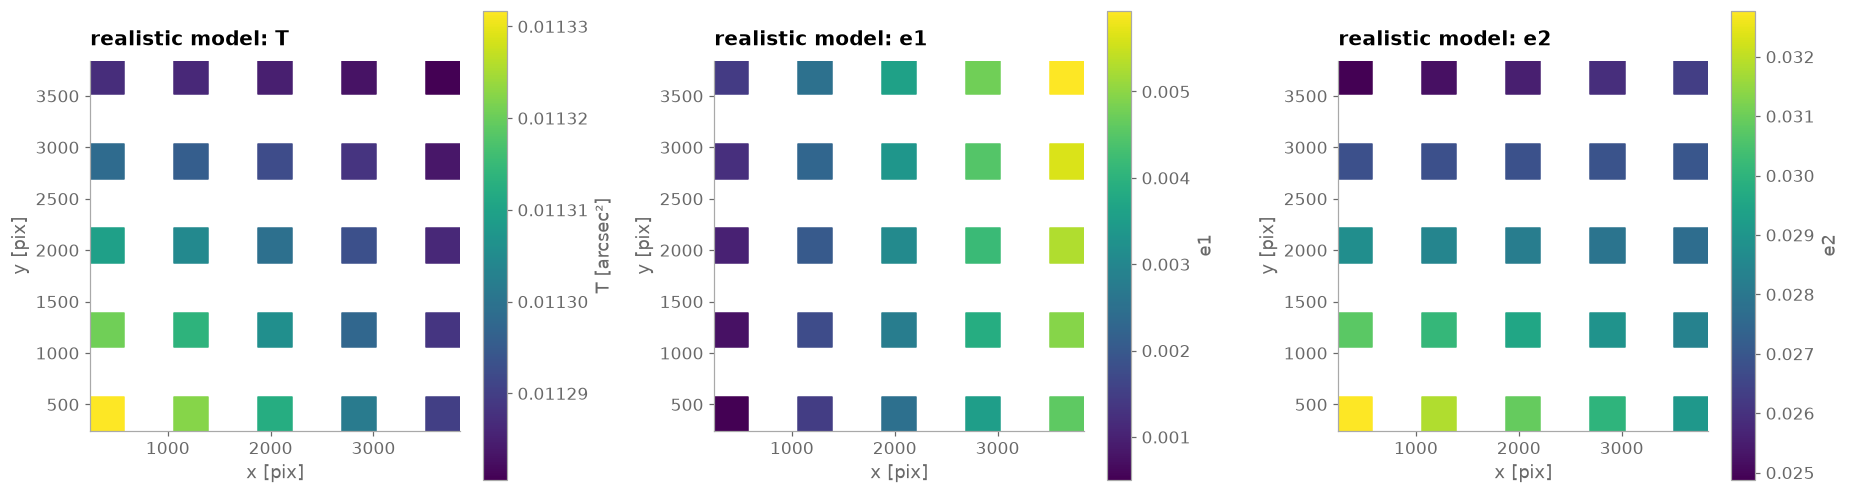

In [15]:
mm = fits["realistic"].model_moments(n_grid=5)    # default algorithms=("hsm",), oversample=5
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
for ax, (q, label) in zip(axes, QUANTITIES.items()):
    sc = ax.scatter(mm["x"], mm["y"], c=mm[q], s=500, marker="s", cmap="viridis")
    fig.colorbar(sc, ax=ax, label=label)
    ax.set(title=f"realistic model: {q}", xlabel="x [pix]", ylabel="y [pix]", aspect="equal")
    ax.grid(False)
fig.tight_layout()
plt.show()

In [16]:
diff = compare_fits(fits)                  # realistic − pinned at the pinned fit's stars
diff = diff[(diff["fit"] == "realistic") & (diff["flag"] == 0)]
fmt(Table(rows=[{"fits": "realistic − pinned", "n": len(diff),
                 **{f"{q}_mean": np.mean(diff[q]) for q in ("dT_T", "de1", "de2")},
                 **{f"{q}_std": np.std(diff[q]) for q in ("dT_T", "de1", "de2")}}]))

/tmp/ipykernel_359362/895962487.py:8: FutureWarning: Format strings passed to MaskedConstant are ignored, but in future may error or produce different behavior
  return f"{v:.4g}" if 1e-3 <= abs(v) < 1 else f"{v:.3e}"


fits,n,dT_T_mean,de1_mean,de2_mean,dT_T_std,de1_std,de2_std
str18,int64,float64,float64,float64,float64,float64,float64
realistic − pinned,80,-0.006565,-0.003784,-0.004801,0.001304,8.999e-04,0.002094


**Each component on its own** (as in `03_piff_validation.ipynb`): every component of the
realistic model at the SCA center, native (top) and oversampled ×5 (bottom), with the native
pixel response.

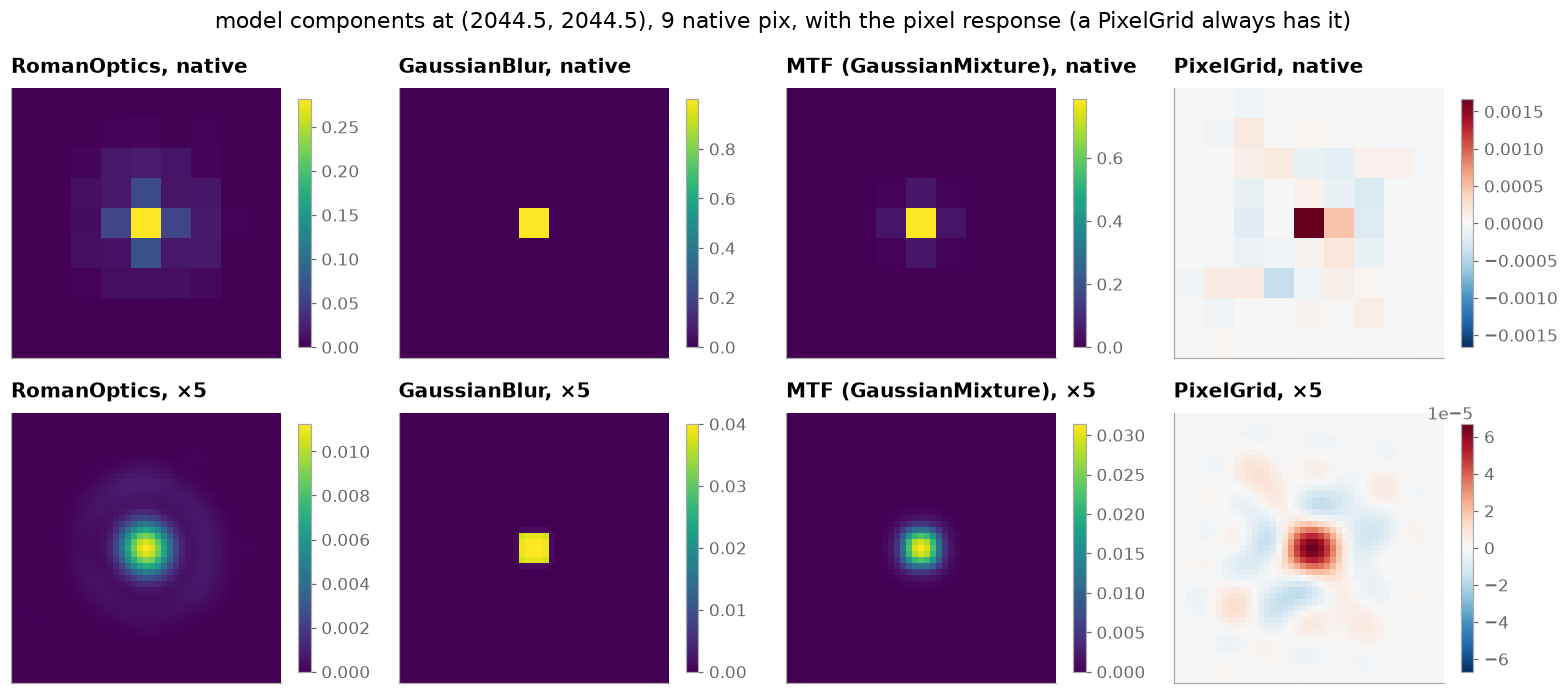

In [17]:
fits["realistic"].plot_component_images()
plt.show()

**Only for synthetic data: the truth.** The simulation knows the true PSF of every star, so
the model can be compared with it: `hsm` on the model and on the true PSF, both oversampled ×5
at the star positions (the same pixels as in the simulation). Mean model − truth over the
stars ± error on the mean.

In [18]:
def truth_errors(res, sim, sca=5):
    t = res.table[res.table["flag"] == 0]
    model = res.model_moments(x=t["x"], y=t["y"])          # hsm, oversampled ×5
    rows = []
    for star_id, m in zip(t["star_id"], model):
        true = sim.truth_psf(sca, 0, int(star_id) - 1, oversample=5)   # catalog id = sim id + 1
        tr = measure_star(make_star(true, true.true_center), "hsm")
        rows.append({"dT_T": m["T"] / tr["T"] - 1, "de1": m["e1"] - tr["e1"],
                     "de2": m["e2"] - tr["e2"]})
    return Table(rows=rows)


rows = []
for label, res in fits.items():
    e = truth_errors(res, sim)
    rows.append({"model": label, "n": len(e),
                 **{q: np.mean(e[q]) for q in ("dT_T", "de1", "de2")},
                 **{q + "_err": np.std(e[q], ddof=1) / np.sqrt(len(e))
                    for q in ("dT_T", "de1", "de2")}})
fmt(Table(rows=rows))

/tmp/ipykernel_359362/895962487.py:8: FutureWarning: Format strings passed to MaskedConstant are ignored, but in future may error or produce different behavior
  return f"{v:.4g}" if 1e-3 <= abs(v) < 1 else f"{v:.3e}"


model,n,dT_T,de1,de2,dT_T_err,de1_err,de2_err
str9,int64,float64,float64,float64,float64,float64,float64
pinned,80,0.009259,0.004396,0.005808,2.492e-04,1.009e-04,9.570e-05
realistic,80,0.00263,6.125e-04,0.001007,1.539e-04,1.430e-05,1.417e-04


## A.6 Reference optimum

As in `03_piff_validation.ipynb`: the best χ² of the same model with all its parameters fitted
at once. Real data have no true star centers, so they are held at Piff's fitted ones
(`centers="fitted"`, the default here). The optics are frozen at Piff's values to keep it
fast; `report="fit"` draws only the fit stars. The moment columns are the data − model
residuals (`comparison="data"`).

In [19]:
real_fit = fits["realistic"]
out = real_fit.reference(freeze=("optics",), starts=("given", "zero"), report="fit")
# defaults: freeze=(), starts=("given",), max_nfev=50, centers="fitted", report="all"
ref_table = comparison_table({"Piff": real_fit,
                              "Piff, profiled": out["given"],
                              "optimum (from Piff)": out["optimum"]["given"],
                              "optimum (from zero)": out["optimum"]["zero"]},
                             comparison="data", algorithm="wmom_0.4")
fmt(ref_table["label", "chisq_dof", "flux_cat_r", "dT_T", "de1", "de2", "converged"])

/tmp/ipykernel_359362/895962487.py:8: FutureWarning: Format strings passed to MaskedConstant are ignored, but in future may error or produce different behavior
  return f"{v:.4g}" if 1e-3 <= abs(v) < 1 else f"{v:.3e}"


label,chisq_dof,flux_cat_r,dT_T,de1,de2,converged
str19,float64,float64,float64,float64,float64,str4
Piff,0.01046,0.9958,-0.003334,-1.897e-04,1.625e-04,True
"Piff, profiled",0.01045,0.9958,-0.003334,-1.897e-04,1.625e-04,
optimum (from Piff),0.01031,1.0284,-0.00135,-6.266e-04,-4.205e-04,True
optimum (from zero),0.01031,1.0310,-0.00111,-6.172e-04,-4.098e-04,True


# Part B: your own L2 file

The same steps for a real L2 file (converted from ASDF to FITS) and its detection catalog.
Set the two paths below; until then every cell of part B is skipped.

What changes for real data:

- the catalog holds galaxies too: `select_stars("sizemag")` (Piff's star finder), or, for a
  catalog already trimmed to stars, the experimental `select_locus` (see `docs/piff_datafit.md`);
- the `clean` flag of SEP catalogs may reject many stars (a masked pixel anywhere in the
  object's aperture); `set_cuts(clean_only=False)` with `reject_where` on chosen flags
  (passed with `extra_cols`) gives more control;
- bright stars saturate: limit the magnitude range, or raise `min_snr` / use `max_pixel_cut`;
- Piff's default `max_snr_weight` (100) caps the weight of bright stars, so χ²/dof falls below
  1 for them; `max_snr_weight=0` turns the cap off.

If you already have a fits image and detection catalog:

In [20]:
IMAGE = None        # e.g. "data/011_wfi05_cal.fits"
CATALOG = None      # e.g. "data/011_wfi05_det.fits"
REAL = IMAGE is not None and CATALOG is not None
print("part B runs" if REAL else "part B is skipped: set IMAGE and CATALOG")

part B is skipped: set IMAGE and CATALOG


You can also use an asdf to fits converter and run sep from psf-fomo:

In [ ]:
## 
from pathlib import Path
from psf_fomo.utils import convert_to_dir, detect_sources, plot_detections, plot_detection_sizes

ASDF = None        # e.g. "data/011_wfi05_cal.asdf"
FITS_DIR = "data"  # direcory where the converted FITS file goes
REAL = ASDF is not None
print("part B runs" if REAL else "part B is skipped: set ASDF")

if REAL:
    IMAGE = Path(FITS_DIR) / (Path(ASDF).stem + ".fits")
    if not IMAGE.exists():             # convert once; overwrite=True redoes it
        convert_asdf_to_fits(ASDF, FITS_DIR, uniform_weights=True)
    detections = detect_sources(IMAGE, metadata=ASDF)             # every detection
    CATALOG = detect_sources(IMAGE, gaia=True, metadata=ASDF)     # Gaia-matched only, for all detections turn off
    # defaults: detection_config={"thresh": 3.0}, match_radius_arcsec=0.11;
    # gaia_catalog="my_gaia.csv" avoids querying the Gaia archive

In [ ]:
if REAL:
    img_real = L2Image(IMAGE)              # add variant="standard" without the uniform planes
    print(f"SCA {img_real.sca}, filter {img_real.filter_name}, sky {img_real.sky:.3f} DN/s")
    print("orientation:", img_real.check_orientation())
    print("weights:    ", img_real.check_weights())
    print("non-finite: ", img_real.check_finite())

In [ ]:
if REAL:
    cat_real = StarCatalog(CATALOG)        # e.g. extra_cols=["extract_flag"] for reject_where
    cat_real.select_stars("sizemag")       # Piff's SizeMag, measured with gauss
    cat_real.set_cuts(clean_only=True, min_snr=50, min_sep=2.5, max_mask_pixels=5)
    # e.g. set_cuts(clean_only=False, reject_where="(extract_flag & 1) != 0", ...)
    plot_image(img_real, cat_real, f"SCA {img_real.sca} [DN/s]")
    plt.show()

In [ ]:
if REAL:
    measured_real = cat_real.measure(img_real, algorithms=("gauss", "wmom"),
                                     preview_selection=True, mag_range=(17, 23))
    print(f"{len(measured_real)} detections measured, {int(measured_real['star'].sum())} "
          "pass the selection and the cuts")
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
    plot_size_mag(measured_real, algorithm="gauss", ax=axes[0])
    plot_size_mag(measured_real, algorithm="wmom_0.4", ax=axes[1])
    fig.tight_layout()
    plt.show()
    # For a catalog of stars only: locus = cat_real.select_locus(measured_real); locus.plot()

In [ ]:
if REAL:
    real_fits = {"pinned": data_fit(img_real, cat_real, pinned, "pinned"),
                 "realistic": data_fit(img_real, cat_real, realistic, "realistic")}
    display(fit_table(real_fits))
    print(real_fits["realistic"].checks)

In [ ]:
if REAL:
    plot_residuals(real_fits)
    plt.show()
    plot_data_vs_model(real_fits)
    plt.show()
    real_fits["realistic"].plot_field("sky_resid")
    plt.show()
    real_fits["realistic"].plot_component_images()
    plt.show()

## Saving and reloading

A fit can be saved to a folder (Piff's `psf.fits`, the star and selection tables, moments,
the Piff catalog and configuration, a cleaned image copy if one was needed, and the
settings) and reloaded. The cells are commented out so that running the notebook writes
nothing.

In [ ]:
# res = PiffDataFit(img, cat, realistic, name="realistic").run(save_to="out/real01")
# from psf_fomo.piff_datafit import load_data_fit
# res = load_data_fit("out/real01")

# Keep the synthetic files instead of a temporary folder:
# synth = simulation_to_l2(sim, sca=5, folder="out/synthetic")